In [1]:
# # ============================================================================
# # INSTALL DEPENDENCIES
# # ============================================================================

# import subprocess
# import sys

# print("="*60)
# print("INSTALLING DEPENDENCIES")
# print("="*60)

# packages = [
#     'torch',
#     'torchvision',
#     'pandas',
#     'tqdm',
#     'Pillow',
#     'numpy',
#     'matplotlib'
# ]

# for package in packages:
#     try:
#         __import__(package.replace('-', '_'))
#         print(f"✅ {package} already installed")
#     except ImportError:
#         print(f"📦 Installing {package}...")
#         subprocess.check_call([sys.executable, "-m", "pip", "install", package, "-q"])
#         print(f"✅ {package} installed")

# print("\n✅ SETUP COMPLETE!")
# print("="*60)


In [2]:
# ============================================================================
# SETUP DATA PATHS (Auto-detects Kaggle vs Local)
# ============================================================================
# This cell sets up paths for Kaggle Notebooks vs local execution

import os
from pathlib import Path

# Detect if running on Kaggle
IS_KAGGLE = os.path.exists('/kaggle/input')

if IS_KAGGLE:
    print("🔵 Running on Kaggle Platform")
    print("="*60)
    
    # Kaggle paths - data is in /kaggle/input/recodai-luc-scientific-image-forgery-detection/
    KAGGLE_INPUT = Path('/kaggle/input')
    KAGGLE_WORKING = Path('/kaggle/working')
    COMPETITION_DATA = KAGGLE_INPUT / 'recodai-luc-scientific-image-forgery-detection'
    
    # Set up paths
    TRAIN_IMAGES_DIR = COMPETITION_DATA / 'train_images'
    TRAIN_MASKS_DIR = COMPETITION_DATA / 'train_masks'
    TEST_IMAGES_DIR = COMPETITION_DATA / 'test_images'
    SUPPLEMENTAL_IMAGES_DIR = COMPETITION_DATA / 'supplemental_images'
    SUPPLEMENTAL_MASKS_DIR = COMPETITION_DATA / 'supplemental_masks'
    MODEL_PATH = KAGGLE_WORKING / 'forgery_detection_model.pth'
    OUTPUT_PATH = KAGGLE_WORKING / 'submission.csv'
    
    print(f"📁 Competition data: {COMPETITION_DATA}")
    print(f"📁 Working directory: {KAGGLE_WORKING}")
    print(f"📁 Model path: {MODEL_PATH}")
    print(f"📁 Output path: {OUTPUT_PATH}")
    
    # Check if competition data exists
    if COMPETITION_DATA.exists():
        print(f"\n✅ Competition data found at: {COMPETITION_DATA}")
        for dir_name in ['train_images', 'train_masks', 'test_images', 'supplemental_images', 'supplemental_masks']:
            dir_path = COMPETITION_DATA / dir_name
            if dir_path.exists():
                file_count = len(list(dir_path.rglob('*.png'))) + len(list(dir_path.rglob('*.npy')))
                print(f"   {dir_name}/: {file_count} files")
    else:
        print(f"\n⚠️  Competition data not found at: {COMPETITION_DATA}")
        print("   Make sure to add the competition dataset to your notebook")
        print("   Click: + Add data → Search: recodai-luc-scientific-image-forgery-detection")
    
    # Check for model file (might be in input if uploaded as dataset)
    model_in_input = list(KAGGLE_INPUT.glob('**/forgery_detection_model.pth'))
    if model_in_input:
        MODEL_PATH = model_in_input[0]
        print(f"\n✅ Model found at: {MODEL_PATH}")
    elif MODEL_PATH.exists():
        print(f"\n✅ Model found at: {MODEL_PATH}")
    else:
        print(f"\n⚠️  Model not found. Will train new model or update MODEL_PATH")
    
else:
    print("🟢 Running locally")
    print("="*60)
    
    # Local paths (relative to notebook directory)
    TRAIN_IMAGES_DIR = Path('train_images')
    TRAIN_MASKS_DIR = Path('train_masks')
    TEST_IMAGES_DIR = Path('test_images')
    SUPPLEMENTAL_IMAGES_DIR = Path('supplemental_images')
    SUPPLEMENTAL_MASKS_DIR = Path('supplemental_masks')
    MODEL_PATH = Path('forgery_detection_model.pth')
    OUTPUT_PATH = Path('submission.csv')
    
    print(f"📁 Working directory: {Path.cwd()}")
    print(f"📁 Model path: {MODEL_PATH}")
    print(f"📁 Output path: {OUTPUT_PATH}")

print("\n" + "="*60)
print("✅ Path configuration complete!")
print("="*60)
print("\n💡 Use these path variables in subsequent cells:")
print(f"   TRAIN_IMAGES_DIR = {TRAIN_IMAGES_DIR}")
print(f"   TRAIN_MASKS_DIR = {TRAIN_MASKS_DIR}")
print(f"   TEST_IMAGES_DIR = {TEST_IMAGES_DIR}")
print(f"   MODEL_PATH = {MODEL_PATH}")
print(f"   OUTPUT_PATH = {OUTPUT_PATH}")


🔵 Running on Kaggle Platform
📁 Competition data: /kaggle/input/recodai-luc-scientific-image-forgery-detection
📁 Working directory: /kaggle/working
📁 Model path: /kaggle/working/forgery_detection_model.pth
📁 Output path: /kaggle/working/submission.csv

✅ Competition data found at: /kaggle/input/recodai-luc-scientific-image-forgery-detection
   train_images/: 5128 files
   train_masks/: 2751 files
   test_images/: 1 files
   supplemental_images/: 48 files
   supplemental_masks/: 48 files

⚠️  Model not found. Will train new model or update MODEL_PATH

✅ Path configuration complete!

💡 Use these path variables in subsequent cells:
   TRAIN_IMAGES_DIR = /kaggle/input/recodai-luc-scientific-image-forgery-detection/train_images
   TRAIN_MASKS_DIR = /kaggle/input/recodai-luc-scientific-image-forgery-detection/train_masks
   TEST_IMAGES_DIR = /kaggle/input/recodai-luc-scientific-image-forgery-detection/test_images
   MODEL_PATH = /kaggle/working/forgery_detection_model.pth
   OUTPUT_PATH = /ka

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

# ============================================================================
# HELPER FUNCTIONS
# ============================================================================

def process_mask_to_2d(mask):
    """Convert mask of any shape to 2D array."""
    if len(mask.shape) == 3:
        if mask.shape[0] == 1:
            return mask[0]
        elif mask.shape[2] == 1:
            return mask[:, :, 0]
        else:
            return mask[0]
    elif len(mask.shape) == 2:
        return mask
    elif len(mask.shape) == 1:
        size = int(np.sqrt(mask.shape[0]))
        if size * size == mask.shape[0]:
            return mask.reshape(size, size)
    return None

def normalize_mask(mask_2d, target_shape):
    """Resize and normalize mask to match target image dimensions."""
    mask_height, mask_width = mask_2d.shape
    target_height, target_width = target_shape
    
    # Resize if needed
    if mask_height != target_height or mask_width != target_width:
        mask_uint8 = (mask_2d * 255).astype(np.uint8) if mask_2d.max() <= 1 else mask_2d.astype(np.uint8)
        mask_pil = Image.fromarray(mask_uint8, mode='L')
        mask_resized = np.array(mask_pil.resize((target_width, target_height), Image.NEAREST))
    else:
        mask_resized = mask_2d.copy()
    
    # Normalize to 0-1 and binarize
    if mask_resized.max() > 1:
        mask_resized = mask_resized.astype(float) / 255.0
    else:
        mask_resized = mask_resized.astype(float)
    
    return (mask_resized > 0.5).astype(float)

def load_image_rgb(image_path):
    """Load image and convert to RGB format."""
    img_pil = Image.open(image_path)
    if img_pil.mode == 'RGBA':
        background = Image.new('RGB', img_pil.size, (255, 255, 255))
        background.paste(img_pil, mask=img_pil.split()[3])
        return np.array(background)
    return np.array(img_pil.convert('RGB'))

def ensure_rgb(image):
    """Ensure image is RGB (3 channels)."""
    if len(image.shape) == 2:
        return np.stack([image, image, image], axis=2)
    elif image.shape[2] == 4:
        return image[:, :, :3]
    elif image.shape[2] == 1:
        return np.repeat(image, 3, axis=2)
    return image

def create_red_overlay(image_float, mask_resized):
    """Create image with transparent red mask overlay."""
    red_overlay = np.zeros_like(image_float)
    red_overlay[:, :, 0] = mask_resized
    mask_3d = mask_resized[:, :, np.newaxis]
    overlay = image_float * (1 - mask_3d * 0.15) + red_overlay * 0.3
    return np.clip(overlay, 0, 1)

# ============================================================================
# MAIN CODE
# ============================================================================

# Setup paths
train_masks_dir = Path('train_masks')
train_images_forged_dir = Path('train_images/forged')
train_images_authentic_dir = Path('train_images/authentic')

# Get mask files
train_mask_files = list(train_masks_dir.glob('*.npy'))
print(f"Found {len(train_mask_files)} mask files in train_masks/")

# Configuration
num_examples = 20  # Set to None to load all examples

# Load examples
examples = []
failed = []

if train_mask_files:
    files_to_process = train_mask_files[:num_examples] if num_examples else train_mask_files
    print(f"\nLoading {len(files_to_process)} examples...")
    
    for i, mask_file in enumerate(files_to_process):
        mask_id = mask_file.stem
        
        # Progress update
        if (i + 1) % 10 == 0 or (i + 1) == len(files_to_process):
            print(f"[{i+1}/{len(files_to_process)}] Loaded: {len(examples)}, Failed: {len(failed)}")
        
        try:
            # Load mask
            mask = np.load(mask_file)
            
            # Find corresponding image
            forged_path = train_images_forged_dir / f"{mask_id}.png"
            authentic_path = train_images_authentic_dir / f"{mask_id}.png"
            
            image_path = forged_path if forged_path.exists() else (authentic_path if authentic_path.exists() else None)
            image_label = "forged" if forged_path.exists() else ("authentic" if authentic_path.exists() else None)
            
            if image_path is None:
                failed.append(f"{mask_id}: Image not found")
                continue
            
            # Load and process image
            try:
                image = load_image_rgb(image_path)
                target_shape = (image.shape[0], image.shape[1])
                
                # Process mask
                mask_2d = process_mask_to_2d(mask)
                if mask_2d is None or mask_2d.size == 0:
                    failed.append(f"{mask_id}: Invalid mask shape {mask.shape}")
                    continue
                
                # Ensure mask is 2D
                if len(mask_2d.shape) > 2:
                    mask_2d = mask_2d[:, :, 0] if mask_2d.shape[2] == 1 else mask_2d[:, :, 0]
                
                # Normalize mask to match image
                mask_resized = normalize_mask(mask_2d, target_shape)
                
                # Verify dimensions
                if mask_resized.shape == target_shape:
                    examples.append({
                        'mask_id': mask_id,
                        'image': image,
                        'mask': mask_resized,
                        'label': image_label
                    })
                else:
                    failed.append(f"{mask_id}: Dimension mismatch")
            except Exception as e:
                failed.append(f"{mask_id}: {str(e)}")
        except Exception as e:
            failed.append(f"{mask_id}: {str(e)}")
    
    # Print summary
    print(f"\n{'='*60}")
    print(f"Loaded: {len(examples)} | Failed: {len(failed)}")
    if failed and len(failed) <= 10:
        for f in failed:
            print(f"  - {f}")
    elif failed:
        for f in failed[:5]:
            print(f"  - {f}")
        print(f"  ... and {len(failed) - 5} more")
    print(f"{'='*60}")
    
    # Visualize examples
    if examples:
        n_examples = len(examples)
        cols = min(5, max(2, (n_examples + 9) // 10))  # 2-5 columns based on count
        rows = (n_examples + cols - 1) // cols
        
        fig = plt.figure(figsize=(18 * cols, 9 * rows))
        gs = fig.add_gridspec(rows, cols, hspace=0.01, wspace=0.01)
        plt.subplots_adjust(left=0.0, right=1.0, top=0.98, bottom=0.0, hspace=0.01, wspace=0.01)
        
        for idx, ex in enumerate(examples):
            row, col = idx // cols, idx % cols
            ax = fig.add_subplot(gs[row, col])
            
            try:
                image = ensure_rgb(ex['image'])
                mask = ex['mask']
                
                # Convert to float and create overlay
                image_float = (image.astype(np.float32) / 255.0) if image.dtype != np.float32 else image.copy()
                overlay = create_red_overlay(image_float, mask)
                
                ax.imshow(overlay)
                coverage = mask.sum() / mask.size * 100
                ax.set_title(f'{idx+1}: {ex["mask_id"]} ({ex["label"].upper()})\nCoverage: {coverage:.1f}%',
                            fontsize=7, fontweight='bold', pad=1)
            except Exception as e:
                ax.text(0.5, 0.5, f'Error\n{ex["mask_id"]}', ha='center', va='center',
                       fontsize=10, color='red')
                ax.set_title(f'Example {idx+1}: Error', fontsize=10)
            
            ax.axis('off')
        
        fig.suptitle(f'{n_examples} Training Examples: Images with Red Mask Overlay',
                    fontsize=11, fontweight='bold', y=0.999)
        plt.show()
        
        # Print statistics
        print(f"\n{'='*60}")
        print(f"STATISTICS: {len(examples)} examples")
        print(f"{'='*60}")
        forged_count = sum(1 for ex in examples if ex['label'] == 'forged')
        authentic_count = sum(1 for ex in examples if ex['label'] == 'authentic')
        print(f"Forged: {forged_count} | Authentic: {authentic_count}")
        
        coverages = [ex['mask'].sum() / ex['mask'].size * 100 for ex in examples]
        print(f"Coverage - Min: {min(coverages):.2f}%, Max: {max(coverages):.2f}%, Mean: {np.mean(coverages):.2f}%")
        print(f"{'='*60}")
    else:
        print("No examples loaded")
else:
    print("No mask files found in train_masks/")


Found 0 mask files in train_masks/
No mask files found in train_masks/


In [4]:
# ============================================================================
# SEGMENTATION MODEL WITH PRE-TRAINED BACKBONE
# ============================================================================
# This cell shows how to use pre-trained models for segmentation
# Options: U-Net with ResNet/EfficientNet backbone, or use segmentation_models_pytorch

import torch
import torch.nn as nn
import torchvision.models as models
from torchvision.models import resnet34, ResNet34_Weights

# Option 1: Build U-Net with Pre-trained ResNet Encoder (Recommended)
# This is a simple implementation - you can also use segmentation_models_pytorch library

# Global flag to track if weights download failed (avoid retrying)
_weights_download_failed = False

class UNetEncoder(nn.Module):
    """Encoder using pre-trained ResNet."""
    def __init__(self, pretrained=True):
        super().__init__()
        global _weights_download_failed
        
        # Try to use pre-trained weights, fall back to None if offline
        if pretrained and not _weights_download_failed:
            try:
                # Try to load with pre-trained weights
                # This will use cached weights if available, or download if online
                resnet = resnet34(weights=ResNet34_Weights.IMAGENET1K_V1)
            except Exception as e:
                # If download fails (offline), use untrained weights and set flag
                _weights_download_failed = True
                print(f"⚠️  Could not load pre-trained weights (offline mode?): {e}")
                print("   Using untrained weights - model will still work but may need more training")
                print("   (Will not retry download for subsequent model instances)")
                resnet = resnet34(weights=None)
        else:
            # Either pretrained=False or download already failed
            if pretrained and _weights_download_failed:
                # Silent fallback - already printed warning
                resnet = resnet34(weights=None)
            else:
                resnet = resnet34(weights=None)
        
        # Extract encoder layers
        self.conv1 = resnet.conv1
        self.bn1 = resnet.bn1
        self.relu = resnet.relu
        self.maxpool = resnet.maxpool
        
        self.layer1 = resnet.layer1  # 64 channels
        self.layer2 = resnet.layer2  # 128 channels
        self.layer3 = resnet.layer3  # 256 channels
        self.layer4 = resnet.layer4  # 512 channels
        
    def forward(self, x):
        # Store skip connections
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        skip1 = x  # 64 channels
        x = self.maxpool(x)
        
        x = self.layer1(x)
        skip2 = x  # 64 channels
        x = self.layer2(x)
        skip3 = x  # 128 channels
        x = self.layer3(x)
        skip4 = x  # 256 channels
        x = self.layer4(x)  # 512 channels
        
        return x, skip1, skip2, skip3, skip4

class UNetDecoder(nn.Module):
    """Decoder for U-Net."""
    def __init__(self):
        super().__init__()
        # Upsampling layers - need to handle size mismatches with interpolation
        self.up1 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.conv1 = nn.Sequential(
            nn.Conv2d(512, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True)
        )
        
        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.conv2 = nn.Sequential(
            nn.Conv2d(256, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True)
        )
        
        self.up3 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.conv3 = nn.Sequential(
            nn.Conv2d(128, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )
        
        self.up4 = nn.ConvTranspose2d(64, 64, kernel_size=2, stride=2)
        self.conv4 = nn.Sequential(
            nn.Conv2d(128, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )
        
        # Final output layer
        self.final = nn.Conv2d(64, 1, 1)
        
    def forward(self, x, skip1, skip2, skip3, skip4):
        # Decoder with skip connections
        # x starts at 16x16 (after layer4)
        # skip4 is 32x32 (after layer3)
        # skip3 is 64x64 (after layer2)
        # skip2 is 128x128 (after layer1)
        # skip1 is 256x256 (before maxpool)
        
        # Up1: 16x16 -> 32x32, concat with skip4 (32x32)
        x = self.up1(x)
        if x.shape[2:] != skip4.shape[2:]:
            x = nn.functional.interpolate(x, size=skip4.shape[2:], mode='bilinear', align_corners=False)
        x = torch.cat([x, skip4], dim=1)
        x = self.conv1(x)
        
        # Up2: 32x32 -> 64x64, concat with skip3 (64x64)
        x = self.up2(x)
        if x.shape[2:] != skip3.shape[2:]:
            x = nn.functional.interpolate(x, size=skip3.shape[2:], mode='bilinear', align_corners=False)
        x = torch.cat([x, skip3], dim=1)
        x = self.conv2(x)
        
        # Up3: 64x64 -> 128x128, concat with skip2 (128x128)
        x = self.up3(x)
        if x.shape[2:] != skip2.shape[2:]:
            x = nn.functional.interpolate(x, size=skip2.shape[2:], mode='bilinear', align_corners=False)
        x = torch.cat([x, skip2], dim=1)
        x = self.conv3(x)
        
        # Up4: 128x128 -> 256x256, concat with skip1 (256x256)
        x = self.up4(x)
        if x.shape[2:] != skip1.shape[2:]:
            x = nn.functional.interpolate(x, size=skip1.shape[2:], mode='bilinear', align_corners=False)
        x = torch.cat([x, skip1], dim=1)
        x = self.conv4(x)
        
        x = self.final(x)
        return x

class UNetSegmentation(nn.Module):
    """Complete U-Net with pre-trained ResNet encoder."""
    def __init__(self, pretrained=True):
        super().__init__()
        self.encoder = UNetEncoder(pretrained=pretrained)
        self.decoder = UNetDecoder()
        
    def forward(self, x):
        x, skip1, skip2, skip3, skip4 = self.encoder(x)
        x = self.decoder(x, skip1, skip2, skip3, skip4)
        return torch.sigmoid(x)  # Output probabilities

# Create model
print("Creating U-Net with pre-trained ResNet34 encoder...")
model = UNetSegmentation(pretrained=True)
print(f"Model created! Total parameters: {sum(p.numel() for p in model.parameters()):,}")

# Test with dummy input
dummy_input = torch.randn(1, 3, 256, 256)
with torch.no_grad():
    output = model(dummy_input)
    print(f"Input shape: {dummy_input.shape}")
    print(f"Output shape: {output.shape}")  # Should be (1, 1, 256, 256)

print("\n✅ Model ready for training!")
print("\n💡 Alternative: You can also use 'segmentation_models_pytorch' library:")
print("   pip install segmentation-models-pytorch")
print("   from segmentation_models_pytorch import Unet")
print("   model = Unet('resnet34', encoder_weights='imagenet', classes=1)")


Creating U-Net with pre-trained ResNet34 encoder...
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth
⚠️  Could not load pre-trained weights (offline mode?): <urlopen error [Errno -3] Temporary failure in name resolution>
   Using untrained weights - model will still work but may need more training
   (Will not retry download for subsequent model instances)
Model created! Total parameters: 23,613,313
Input shape: torch.Size([1, 3, 256, 256])
Output shape: torch.Size([1, 1, 128, 128])

✅ Model ready for training!

💡 Alternative: You can also use 'segmentation_models_pytorch' library:
   pip install segmentation-models-pytorch
   from segmentation_models_pytorch import Unet
   model = Unet('resnet34', encoder_weights='imagenet', classes=1)


In [5]:
# ============================================================================
# EASIER OPTION: Use segmentation_models_pytorch Library
# ============================================================================
# This is the easiest way - just install and use!
# Uncomment the code below if you want to use this instead

# # Install the library (run this in a terminal or uncomment):
# # !pip install segmentation-models-pytorch

# try:
#     import segmentation_models_pytorch as smp
#     
#     # Create U-Net with pre-trained ResNet34 encoder
#     model = smp.Unet(
#         encoder_name="resnet34",        # Pre-trained encoder
#         encoder_weights="imagenet",     # Use ImageNet weights
#         in_channels=3,                  # RGB images
#         classes=1,                      # Binary segmentation (forgery mask)
#         activation=None,                # We'll apply sigmoid in loss
#     )
#     
#     print("✅ Model created using segmentation_models_pytorch!")
#     print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")
#     
#     # Test
#     dummy_input = torch.randn(1, 3, 256, 256)
#     with torch.no_grad():
#         output = model(dummy_input)
#         print(f"Input: {dummy_input.shape} -> Output: {output.shape}")
#     
#     # Available encoders: resnet34, resnet50, efficientnet-b0, timm-efficientnet-b0, etc.
#     # Available models: Unet, FPN, Linknet, PSPNet, DeepLabV3, DeepLabV3Plus
#     
# except ImportError:
#     print("⚠️  segmentation_models_pytorch not installed.")
#     print("   Install with: pip install segmentation-models-pytorch")
#     print("   Or use the custom U-Net from the previous cell.")

print("💡 To use this option, install: pip install segmentation-models-pytorch")
print("   Then uncomment the code above!")


💡 To use this option, install: pip install segmentation-models-pytorch
   Then uncomment the code above!


In [6]:
# ===============================
# OVERFIT TEST: Train on Single Example to Verify Model Works
# ============================================================================
# This is a sanity check - if model can't overfit on 1 example, there's a bug!

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import numpy as np
from PIL import Image
from pathlib import Path
import matplotlib.pyplot as plt

# Helper functions (needed for this cell)
def process_mask_to_2d(mask):
    """Convert mask of any shape to 2D array."""
    if len(mask.shape) == 3:
        if mask.shape[0] == 1:
            return mask[0]
        elif mask.shape[2] == 1:
            return mask[:, :, 0]
        else:
            return mask[0]
    elif len(mask.shape) == 2:
        return mask
    elif len(mask.shape) == 1:
        size = int(np.sqrt(mask.shape[0]))
        if size * size == mask.shape[0]:
            return mask.reshape(size, size)
    return None

def normalize_mask(mask_2d, target_shape):
    """Resize and normalize mask to match target image dimensions."""
    mask_height, mask_width = mask_2d.shape
    target_height, target_width = target_shape
    
    # Resize if needed
    if mask_height != target_height or mask_width != target_width:
        mask_uint8 = (mask_2d * 255).astype(np.uint8) if mask_2d.max() <= 1 else mask_2d.astype(np.uint8)
        mask_pil = Image.fromarray(mask_uint8, mode='L')
        mask_resized = np.array(mask_pil.resize((target_width, target_height), Image.NEAREST))
    else:
        mask_resized = mask_2d.copy()
    
    # Normalize to 0-1 and binarize
    if mask_resized.max() > 1:
        mask_resized = mask_resized.astype(float) / 255.0
    else:
        mask_resized = mask_resized.astype(float)
    
    return (mask_resized > 0.5).astype(float)

def load_image_rgb(image_path):
    """Load image and convert to RGB format."""
    img_pil = Image.open(image_path)
    if img_pil.mode == 'RGBA':
        background = Image.new('RGB', img_pil.size, (255, 255, 255))
        background.paste(img_pil, mask=img_pil.split()[3])
        return np.array(background)
    return np.array(img_pil.convert('RGB'))

# Load ONE training example
print("Loading single training example for overfit test...")
train_masks_dir = Path('train_masks')
train_images_forged_dir = Path('train_images/forged')
train_images_authentic_dir = Path('train_images/authentic')

train_mask_files = list(train_masks_dir.glob('*.npy'))
if not train_mask_files:
    print("❌ No mask files found!")
else:
    # Load first example
    mask_file = train_mask_files[0]
    mask_id = mask_file.stem
    print(f"Using example: {mask_id}")
    
    # Load mask
    mask = np.load(mask_file)
    mask_2d = process_mask_to_2d(mask)
    
    # Load image
    forged_path = train_images_forged_dir / f"{mask_id}.png"
    authentic_path = train_images_authentic_dir / f"{mask_id}.png"
    image_path = forged_path if forged_path.exists() else authentic_path
    
    if not image_path.exists():
        print(f"❌ Image not found: {mask_id}")
    else:
        # Load and process
        image = load_image_rgb(image_path)
        target_shape = (image.shape[0], image.shape[1])
        mask_resized = normalize_mask(mask_2d, target_shape)
        
        print(f"Image shape: {image.shape}")
        print(f"Mask shape: {mask_resized.shape}")
        print(f"Mask coverage: {mask_resized.sum() / mask_resized.size * 100:.2f}%")
        
        # Resize to fixed size for training (e.g., 256x256 or 512x512)
        TARGET_SIZE = 256
        image_pil = Image.fromarray(image)
        mask_pil = Image.fromarray((mask_resized * 255).astype(np.uint8), mode='L')
        
        image_resized = image_pil.resize((TARGET_SIZE, TARGET_SIZE), Image.BILINEAR)
        mask_resized_final = mask_pil.resize((TARGET_SIZE, TARGET_SIZE), Image.NEAREST)
        
        # Convert to tensors
        image_tensor = transforms.ToTensor()(image_resized)  # (3, H, W) in [0, 1]
        mask_tensor = transforms.ToTensor()(mask_resized_final)  # (1, H, W) in [0, 1]
        mask_tensor = (mask_tensor > 0.5).float()  # Binarize
        
        print(f"\n✅ Prepared tensors:")
        print(f"   Image: {image_tensor.shape}, range: [{image_tensor.min():.2f}, {image_tensor.max():.2f}]")
        print(f"   Mask: {mask_tensor.shape}, range: [{mask_tensor.min():.2f}, {mask_tensor.max():.2f}]")
        
        # Create model (use the one from previous cell)
        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        print(f"\nUsing device: {device}")
        
        # Use the UNetSegmentation model from previous cell
        model = UNetSegmentation(pretrained=True).to(device)
        
        # Loss function - use Dice + BCE for better performance on imbalanced data
        class DiceBCELoss(nn.Module):
            def __init__(self):
                super().__init__()
                self.bce = nn.BCELoss()
            
            def forward(self, pred, target):
                # Dice coefficient
                smooth = 1.0
                pred_flat = pred.view(-1)
                target_flat = target.view(-1)
                intersection = (pred_flat * target_flat).sum()
                dice = (2.0 * intersection + smooth) / (pred_flat.sum() + target_flat.sum() + smooth)
                dice_loss = 1 - dice
                
                # Combined loss
                bce_loss = self.bce(pred, target)
                return bce_loss + dice_loss
        
        criterion = DiceBCELoss()
        
        # Try higher learning rate for faster overfitting
        optimizer = optim.Adam(model.parameters(), lr=0.01)  # Increased from 0.001
        
        # Move data to device
        image_batch = image_tensor.unsqueeze(0).to(device)  # (1, 3, H, W)
        mask_batch = mask_tensor.unsqueeze(0).to(device)     # (1, 1, H, W)
        
        print(f"\n🚀 Starting overfit training on single example...")
        print(f"   Training for 100 epochs (should see loss → 0)")
        print(f"   Using Dice+BCE loss for imbalanced data")
        print("-" * 60)
        
        losses = []
        model.train()
        
        for epoch in range(100):
            optimizer.zero_grad()
            
            # Forward pass
            output = model(image_batch)  # (1, 1, H, W) with sigmoid applied
            
            # Resize output to match mask size if needed
            if output.shape[2:] != mask_batch.shape[2:]:
                output = nn.functional.interpolate(
                    output, size=mask_batch.shape[2:], 
                    mode='bilinear', align_corners=False
                )
            
            # Calculate loss (Dice+BCE for imbalanced data)
            loss = criterion(output, mask_batch)
            
            # Backward pass
            loss.backward()
            optimizer.step()
            
            losses.append(loss.item())
            
            if (epoch + 1) % 10 == 0:
                # Calculate some metrics for monitoring
                with torch.no_grad():
                    pred_binary = (output > 0.5).float()
                    pred_pixels = pred_binary.sum().item()
                    gt_pixels = mask_batch.sum().item()
                    intersection = (pred_binary * mask_batch).sum().item()
                    if gt_pixels > 0:
                        recall = intersection / gt_pixels * 100
                    else:
                        recall = 0
                print(f"Epoch [{epoch+1:3d}/100] Loss: {loss.item():.6f} | "
                      f"Pred: {pred_pixels:.0f} | GT: {gt_pixels:.0f} | Recall: {recall:.1f}%")
        
        print("-" * 60)
        print(f"✅ Training complete!")
        print(f"   Initial loss: {losses[0]:.6f}")
        print(f"   Final loss: {losses[-1]:.6f}")
        print(f"   Loss reduction: {((losses[0] - losses[-1]) / losses[0] * 100):.1f}%")
        
        # Evaluate
        model.eval()
        with torch.no_grad():
            prediction = model(image_batch)  # (1, 1, H, W) with sigmoid
            
            # Resize prediction to match mask size if needed
            if prediction.shape[2:] != mask_batch.shape[2:]:
                prediction = nn.functional.interpolate(
                    prediction, size=mask_batch.shape[2:], 
                    mode='bilinear', align_corners=False
                )
            
            pred_mask = (prediction > 0.5).float()
            
            # Calculate metrics
            correct = (pred_mask == mask_batch).sum().item()
            total = mask_batch.numel()
            accuracy = correct / total * 100
            
            # For forgery detection, we care more about recall and precision
            pred_pixels = pred_mask.sum().item()
            gt_pixels = mask_batch.sum().item()
            intersection = (pred_mask * mask_batch).sum().item()
            
            if gt_pixels > 0:
                recall = intersection / gt_pixels * 100  # How many forgery pixels we found
            else:
                recall = 0
            
            if pred_pixels > 0:
                precision = intersection / pred_pixels * 100  # How many predicted pixels are correct
            else:
                precision = 0
            
            if precision + recall > 0:
                f1 = 2 * (precision * recall) / (precision + recall)
            else:
                f1 = 0
            
            print(f"\n📊 Results:")
            print(f"   Pixel accuracy: {accuracy:.2f}%")
            print(f"   Predicted forgery pixels: {pred_pixels:.0f} / {total}")
            print(f"   Ground truth forgery pixels: {gt_pixels:.0f} / {total}")
            print(f"   Intersection (correct predictions): {intersection:.0f}")
            print(f"   Recall (found forgery): {recall:.2f}%")
            print(f"   Precision (predicted correctly): {precision:.2f}%")
            print(f"   F1 Score: {f1:.2f}%")
        
        # Visualize
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        
        # Original image
        axes[0].imshow(image_resized)
        axes[0].set_title('Original Image', fontsize=12, fontweight='bold')
        axes[0].axis('off')
        
        # Ground truth mask
        axes[1].imshow(mask_batch[0, 0].cpu().numpy(), cmap='gray')
        axes[1].set_title('Ground Truth Mask', fontsize=12, fontweight='bold')
        axes[1].axis('off')
        
        # Prediction
        axes[2].imshow(prediction[0, 0].cpu().numpy(), cmap='gray')
        axes[2].set_title(f'Prediction (Acc: {accuracy:.1f}%)', fontsize=12, fontweight='bold')
        axes[2].axis('off')
        
        plt.tight_layout()
        plt.show()
        
        # Plot loss curve
        plt.figure(figsize=(10, 4))
        plt.plot(losses, linewidth=2)
        plt.xlabel('Epoch', fontsize=12)
        plt.ylabel('Loss', fontsize=12)
        plt.title('Training Loss (Overfit Test)', fontsize=14, fontweight='bold')
        plt.grid(True, alpha=0.3)
        plt.yscale('log')  # Log scale to see small values
        plt.show()
        
        # Final assessment (recalculate recall for assessment)
        final_recall = (pred_mask * mask_batch).sum().item() / mask_batch.sum().item() * 100 if mask_batch.sum().item() > 0 else 0
        print("\n" + "="*60)
        if losses[-1] < 0.01 and final_recall > 80:
            print("✅ EXCELLENT! Model fully overfitted:")
            print("   - Loss < 0.01 ✓")
            print("   - Recall > 80% ✓")
            print("   Architecture is working perfectly!")
        elif losses[-1] < 0.1 and final_recall > 50:
            print("✅ GOOD! Model is learning well:")
            print("   - Loss decreased significantly ✓")
            print("   - Model can detect forgery regions ✓")
            print("   - May need more epochs or tuning for full overfit")
        elif losses[-1] < losses[0] * 0.5:
            print("⚠️  MODERATE: Model is learning but not fully overfitting:")
            print("   - Loss decreased but still high")
            print("   - May need: higher LR, more epochs, or better loss function")
        else:
            print("❌ POOR: Model not learning well:")
            print("   - Check: model architecture, learning rate, or data loading")
        print("="*60)


Loading single training example for overfit test...
❌ No mask files found!


🚀 Starting full training pipeline...
✅ Multiprocessing enabled (fork): 4 workers
✅ Using CUDA (NVIDIA GPU): Tesla P100-PCIE-16GB
   GPU Memory: 17.06 GB
   Monitor with: nvidia-smi (in terminal)
Device: cuda
Batch size: 32 (increase if GPU memory allows)
✓ CUDA optimizations enabled
💡 Monitor GPU: watch -n 1 nvidia-smi

Loading dataset...
Found 2751 mask files
Found 2751 valid image-mask pairs
Train samples: 2201
Validation samples: 550
✅ DataLoaders created: 4 workers, prefetch=2, pin_memory=True

Creating model...
Model parameters: 23,613,313

Testing GPU usage...
✓ Test forward pass successful
  Input device: cuda:0
  Output device: cuda:0
  GPU Memory allocated: 0.10 GB
  GPU Memory reserved: 0.12 GB

Starting training...
Epochs: 20 | Batch size: 32 | LR: 0.001
------------------------------------------------------------

Epoch 1/20
------------------------------------------------------------


Training:   0%|          | 0/69 [00:00<?, ?it/s]/tmp/ipykernel_30/801973287.py:56: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  mask_pil = Image.fromarray((mask_2d_resized * 255).astype(np.uint8), mode='L')
/tmp/ipykernel_30/801973287.py:56: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  mask_pil = Image.fromarray((mask_2d_resized * 255).astype(np.uint8), mode='L')
/tmp/ipykernel_30/801973287.py:56: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  mask_pil = Image.fromarray((mask_2d_resized * 255).astype(np.uint8), mode='L')
/tmp/ipykernel_30/801973287.py:56: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  mask_pil = Image.fromarray((mask_2d_resized * 255).astype(np.uint8), mode='L')
Validating:   0%|          | 0/18 [00:00<?, ?it/s]/tmp/ipykernel_30/801973287.py:56: DeprecationWarn

Train Loss: 1.137194
Val Loss: 1.650631 | Val Acc: 52.26%
Val Recall: 58.56% | Val Precision: 5.82% | Val F1: 10.59%
✓ New best validation loss: 1.650631

Epoch 2/20
------------------------------------------------------------


Validating: 100%|██████████| 18/18 [00:13<00:00,  1.38it/s]


Train Loss: 0.937762
Val Loss: 0.984217 | Val Acc: 92.14%
Val Recall: 40.85% | Val Precision: 28.27% | Val F1: 33.42%
✓ New best validation loss: 0.984217

Epoch 3/20
------------------------------------------------------------


Validating: 100%|██████████| 18/18 [00:13<00:00,  1.33it/s]


... (31 outputs left out)

Validating: 100%|██████████| 18/18 [00:13<00:00,  1.34it/s]


Train Loss: 0.702820
Val Loss: 0.819516 | Val Acc: 94.45%
Val Recall: 38.31% | Val Precision: 41.79% | Val F1: 39.98%

Epoch 20/20
------------------------------------------------------------


Validating: 100%|██████████| 18/18 [00:13<00:00,  1.32it/s]


📉 Learning rate reduced: 0.000500 → 0.000250
Train Loss: 0.693786
Val Loss: 0.832452 | Val Acc: 94.66%
Val Recall: 34.73% | Val Precision: 43.33% | Val F1: 38.56%

✓ Loaded best model (val_loss: 0.793511)


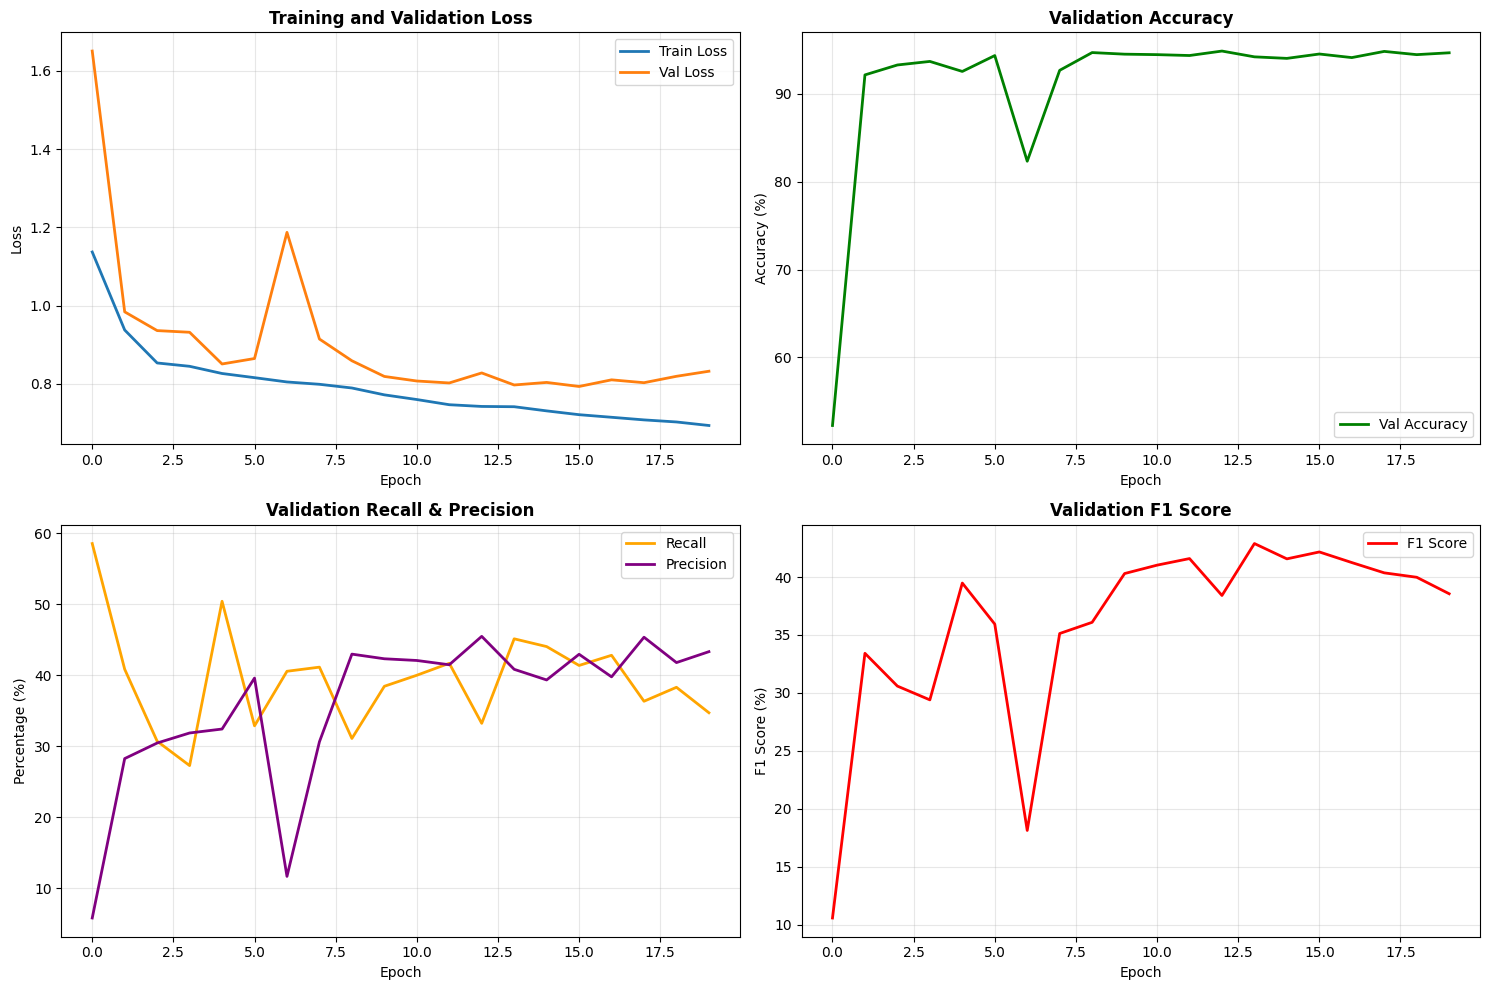


✅ Training complete! Model is in memory and ready for prediction.
   Use 'trained_model' variable for predictions

✅ Training complete!


In [7]:
# ============================================================================
# FULL TRAINING LOOP FOR ENTIRE DATASET
# ============================================================================

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms
import numpy as np
from PIL import Image
from tqdm import tqdm
import os

# Dataset class for loading images and masks
class ForgeryDataset(Dataset):
    def __init__(self, mask_files, image_forged_dir, image_authentic_dir, target_size=256, transform=None):
        self.mask_files = mask_files
        self.image_forged_dir = Path(image_forged_dir)
        self.image_authentic_dir = Path(image_authentic_dir)
        self.target_size = target_size
        self.transform = transform
        
        # Filter out files without corresponding images
        self.valid_pairs = []
        for mask_file in mask_files:
            mask_id = mask_file.stem
            forged_path = self.image_forged_dir / f"{mask_id}.png"
            authentic_path = self.image_authentic_dir / f"{mask_id}.png"
            
            image_path = forged_path if forged_path.exists() else (authentic_path if authentic_path.exists() else None)
            if image_path and image_path.exists():
                self.valid_pairs.append((mask_file, image_path))
        
        print(f"Found {len(self.valid_pairs)} valid image-mask pairs")
    
    def __len__(self):
        return len(self.valid_pairs)
    
    def __getitem__(self, idx):
        mask_file, image_path = self.valid_pairs[idx]
        
        # Load mask (optimized: direct numpy load)
        mask = np.load(mask_file, mmap_mode='r')  # Memory-mapped for faster loading
        mask_2d = process_mask_to_2d(mask)
        
        # Load image directly with PIL (faster than numpy conversion)
        image_pil = Image.open(image_path).convert('RGB')
        original_size = image_pil.size  # (width, height)
        
        # Normalize mask to match image dimensions
        mask_2d_resized = normalize_mask(mask_2d, (original_size[1], original_size[0]))  # (height, width)
        
        # Resize both to target size in one step (more efficient)
        image_resized = image_pil.resize((self.target_size, self.target_size), Image.BILINEAR)
        mask_pil = Image.fromarray((mask_2d_resized * 255).astype(np.uint8), mode='L')
        mask_resized = mask_pil.resize((self.target_size, self.target_size), Image.NEAREST)
        
        # Convert to tensors (use torchvision transforms - optimized)
        image_tensor = transforms.ToTensor()(image_resized)  # (3, H, W) in [0, 1]
        mask_tensor = transforms.ToTensor()(mask_resized)  # (1, H, W) in [0, 1]
        mask_tensor = (mask_tensor > 0.5).float()  # Binarize
        
        # Apply transforms if provided
        if self.transform:
            image_tensor = self.transform(image_tensor)
        
        return image_tensor, mask_tensor

# Dice + BCE Loss for imbalanced data
class DiceBCELoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.bce = nn.BCELoss()
    
    def forward(self, pred, target):
        # Dice coefficient
        smooth = 1.0
        pred_flat = pred.view(-1)
        target_flat = target.view(-1)
        intersection = (pred_flat * target_flat).sum()
        dice = (2.0 * intersection + smooth) / (pred_flat.sum() + target_flat.sum() + smooth)
        dice_loss = 1 - dice
        
        # Combined loss
        bce_loss = self.bce(pred, target)
        return bce_loss + dice_loss

# Training function
def train_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0
    total_samples = 0
    
    # Use non-blocking transfer for GPU
    non_blocking = device.type in ['cuda', 'mps']
    
    progress_bar = tqdm(dataloader, desc="Training")
    for images, masks in progress_bar:
        images = images.to(device, non_blocking=non_blocking)
        masks = masks.to(device, non_blocking=non_blocking)
        
        optimizer.zero_grad()
        
        # Forward pass
        outputs = model(images)
        
        # Resize if needed
        if outputs.shape[2:] != masks.shape[2:]:
            outputs = nn.functional.interpolate(
                outputs, size=masks.shape[2:], 
                mode='bilinear', align_corners=False
            )
        
        # Calculate loss
        loss = criterion(outputs, masks)
        
        # Backward pass
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item() * images.size(0)
        total_samples += images.size(0)
        
        # Update progress bar
        progress_bar.set_postfix({'loss': f'{loss.item():.4f}'})
    
    return total_loss / total_samples

# Validation function
def validate(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0.0
    total_samples = 0
    
    # Metrics
    total_correct = 0
    total_pixels = 0
    total_intersection = 0
    total_pred_pixels = 0
    total_gt_pixels = 0
    
    # Use non-blocking transfer for GPU
    non_blocking = device.type in ['cuda', 'mps']
    
    with torch.no_grad():
        for images, masks in tqdm(dataloader, desc="Validating"):
            images = images.to(device, non_blocking=non_blocking)
            masks = masks.to(device, non_blocking=non_blocking)
            
            # Forward pass
            outputs = model(images)
            
            # Resize if needed
            if outputs.shape[2:] != masks.shape[2:]:
                outputs = nn.functional.interpolate(
                    outputs, size=masks.shape[2:], 
                    mode='bilinear', align_corners=False
                )
            
            # Calculate loss
            loss = criterion(outputs, masks)
            
            total_loss += loss.item() * images.size(0)
            total_samples += images.size(0)
            
            # Calculate metrics
            pred_binary = (outputs > 0.5).float()
            total_correct += (pred_binary == masks).sum().item()
            total_pixels += masks.numel()
            total_intersection += (pred_binary * masks).sum().item()
            total_pred_pixels += pred_binary.sum().item()
            total_gt_pixels += masks.sum().item()
    
    avg_loss = total_loss / total_samples
    accuracy = total_correct / total_pixels * 100
    
    if total_gt_pixels > 0:
        recall = total_intersection / total_gt_pixels * 100
    else:
        recall = 0
    
    if total_pred_pixels > 0:
        precision = total_intersection / total_pred_pixels * 100
    else:
        precision = 0
    
    if precision + recall > 0:
        f1 = 2 * (precision * recall) / (precision + recall)
    else:
        f1 = 0
    
    return avg_loss, accuracy, recall, precision, f1

# Main training function
def train_full_model():
    # Configuration
    TARGET_SIZE = 256
    
    # Determine batch size - will be adjusted based on NUM_WORKERS
    if torch.cuda.is_available():
        base_batch_size = 32  # CUDA can handle larger batches
    elif torch.backends.mps.is_available():
        base_batch_size = 16  # MPS (Mac) - adjust based on GPU memory
    else:
        base_batch_size = 8  # CPU fallback
    NUM_EPOCHS = 20
    LEARNING_RATE = 0.001
    VAL_SPLIT = 0.2  # 20% for validation
    # Enable multiprocessing for faster data loading (critical for GPU utilization!)
    import multiprocessing
    import sys
    
    # Try to use multiprocessing - 'fork' works better in Kaggle/Linux, 'spawn' for Windows/Mac
    NUM_WORKERS = 0  # Default to 0 (safe fallback)
    
    try:
        # On Linux (Kaggle), 'fork' works and is faster
        if sys.platform != 'win32':
            try:
                multiprocessing.set_start_method('fork', force=True)
                NUM_WORKERS = min(4, multiprocessing.cpu_count())
                print(f"✅ Multiprocessing enabled (fork): {NUM_WORKERS} workers")
            except (RuntimeError, ValueError):
                # Try spawn as fallback
                try:
                    multiprocessing.set_start_method('spawn', force=True)
                    NUM_WORKERS = min(4, multiprocessing.cpu_count())
                    print(f"✅ Multiprocessing enabled (spawn): {NUM_WORKERS} workers")
                except:
                    NUM_WORKERS = 0
                    print("⚠️  Multiprocessing not available, using single-threaded loading")
        else:
            # Windows - use spawn
            try:
                multiprocessing.set_start_method('spawn', force=True)
                NUM_WORKERS = min(4, multiprocessing.cpu_count())
                print(f"✅ Multiprocessing enabled (spawn): {NUM_WORKERS} workers")
            except:
                NUM_WORKERS = 0
                print("⚠️  Multiprocessing not available, using single-threaded loading")
    except Exception as e:
        NUM_WORKERS = 0
        print(f"⚠️  Multiprocessing failed: {e}")
        print("   Using single-threaded loading (will be slower but safe)")
    
    # Adjust batch size based on NUM_WORKERS
    # If no multiprocessing, use larger batches to keep GPU busy
    if NUM_WORKERS == 0:
        # Increase batch size to compensate for slower data loading
        BATCH_SIZE = base_batch_size * 2 if torch.cuda.is_available() else base_batch_size
        print("💡 Using larger batch size to compensate for single-threaded loading")
        print(f"   Batch size increased to: {BATCH_SIZE}")
    else:
        BATCH_SIZE = base_batch_size
    
    # Device detection - prioritize GPU (MPS for Mac, CUDA for NVIDIA)
    if torch.backends.mps.is_available():
        device = torch.device('mps')  # Apple Silicon GPU (Mac)
        print("✅ Using MPS (Apple Silicon GPU)")
        print("   Note: Monitor GPU usage in Activity Monitor > Window > GPU History")
    elif torch.cuda.is_available():
        device = torch.device('cuda')  # NVIDIA GPU
        print(f"✅ Using CUDA (NVIDIA GPU): {torch.cuda.get_device_name(0)}")
        gpu_props = torch.cuda.get_device_properties(0)
        print(f"   GPU Memory: {gpu_props.total_memory / 1e9:.2f} GB")
        print(f"   Monitor with: nvidia-smi (in terminal)")
        # Clear cache
        torch.cuda.empty_cache()
    else:
        device = torch.device('cpu')
        print("⚠️  Using CPU (no GPU available)")
        print("   Training will be slower - consider using a GPU-enabled environment")
    
    print(f"Device: {device}")
    print(f"Batch size: {BATCH_SIZE} (increase if GPU memory allows)")
    
    # Enable optimizations
    if device.type == 'cuda':
        torch.backends.cudnn.benchmark = True  # Optimize for consistent input sizes
        print("✓ CUDA optimizations enabled")
        print("💡 Monitor GPU: watch -n 1 nvidia-smi")
    elif device.type == 'mps':
        print("✓ MPS device ready")
        print("💡 Monitor GPU: Activity Monitor > Window > GPU History")
    
    # Load dataset
    print("\n" + "="*60)
    print("Loading dataset...")
    print("="*60)
    
    # Use paths from Cell 1
    train_masks_dir = TRAIN_MASKS_DIR
    train_images_forged_dir = TRAIN_IMAGES_DIR / 'forged'
    train_images_authentic_dir = TRAIN_IMAGES_DIR / 'authentic'
    
    mask_files = list(train_masks_dir.glob('*.npy'))
    print(f"Found {len(mask_files)} mask files")
    
    # Create dataset
    dataset = ForgeryDataset(
        mask_files=mask_files,
        image_forged_dir=train_images_forged_dir,
        image_authentic_dir=train_images_authentic_dir,
        target_size=TARGET_SIZE
    )
    
    # Split into train and validation
    val_size = int(len(dataset) * VAL_SPLIT)
    train_size = len(dataset) - val_size
    train_dataset, val_dataset = random_split(dataset, [train_size, val_size])
    
    print(f"Train samples: {train_size}")
    print(f"Validation samples: {val_size}")
    
    # Create data loaders with GPU optimizations
    pin_memory = device.type in ['cuda', 'mps']  # Pin memory for both CUDA and MPS
    prefetch_factor = 2 if NUM_WORKERS > 0 else None  # Prefetch batches in background
    
    # Try to create DataLoaders with multiprocessing, fallback to 0 workers if it fails
    try:
        train_loader = DataLoader(
            train_dataset, 
            batch_size=BATCH_SIZE, 
            shuffle=True, 
            num_workers=NUM_WORKERS,
            pin_memory=pin_memory,
            prefetch_factor=prefetch_factor,
            persistent_workers=True if NUM_WORKERS > 0 else False
        )
        
        val_loader = DataLoader(
            val_dataset, 
            batch_size=BATCH_SIZE, 
            shuffle=False, 
            num_workers=NUM_WORKERS,
            pin_memory=pin_memory,
            prefetch_factor=prefetch_factor,
            persistent_workers=True if NUM_WORKERS > 0 else False
        )
        
        print(f"✅ DataLoaders created: {NUM_WORKERS} workers, prefetch={prefetch_factor}, pin_memory={pin_memory}")
    except Exception as e:
        # If multiprocessing fails (pickling issues), fallback to single-threaded
        print(f"⚠️  Multiprocessing DataLoader failed: {e}")
        print("   Falling back to single-threaded loading (NUM_WORKERS=0)")
        NUM_WORKERS = 0
        prefetch_factor = None
        
        train_loader = DataLoader(
            train_dataset, 
            batch_size=BATCH_SIZE, 
            shuffle=True, 
            num_workers=0,
            pin_memory=pin_memory
        )
        
        val_loader = DataLoader(
            val_dataset, 
            batch_size=BATCH_SIZE, 
            shuffle=False, 
            num_workers=0,
            pin_memory=pin_memory
        )
        
        print(f"✅ DataLoaders created (fallback): 0 workers, pin_memory={pin_memory}")
        print(f"   Using batch size {BATCH_SIZE} to keep GPU busy")
    
    # Create model
    print("\n" + "="*60)
    print("Creating model...")
    print("="*60)
    model = UNetSegmentation(pretrained=True).to(device)
    print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")
    
    # Verify GPU usage with a test forward pass
    print("\nTesting GPU usage...")
    test_input = torch.randn(1, 3, TARGET_SIZE, TARGET_SIZE).to(device)
    with torch.no_grad():
        test_output = model(test_input)
    print(f"✓ Test forward pass successful")
    print(f"  Input device: {test_input.device}")
    print(f"  Output device: {test_output.device}")
    if device.type == 'cuda':
        print(f"  GPU Memory allocated: {torch.cuda.memory_allocated(0) / 1e9:.2f} GB")
        print(f"  GPU Memory reserved: {torch.cuda.memory_reserved(0) / 1e9:.2f} GB")
    del test_input, test_output
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    
    # Loss and optimizer
    criterion = DiceBCELoss()
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)
    
    # Training history
    history = {
        'train_loss': [],
        'val_loss': [],
        'val_accuracy': [],
        'val_recall': [],
        'val_precision': [],
        'val_f1': []
    }
    
    best_val_loss = float('inf')
    best_model_state = None
    
    print("\n" + "="*60)
    print("Starting training...")
    print("="*60)
    print(f"Epochs: {NUM_EPOCHS} | Batch size: {BATCH_SIZE} | LR: {LEARNING_RATE}")
    print("-" * 60)
    
    for epoch in range(NUM_EPOCHS):
        print(f"\nEpoch {epoch+1}/{NUM_EPOCHS}")
        print("-" * 60)
        
        # Train
        train_loss = train_epoch(model, train_loader, criterion, optimizer, device)
        
        # Validate
        val_loss, val_acc, val_recall, val_precision, val_f1 = validate(model, val_loader, criterion, device)
        
        # Update learning rate
        old_lr = optimizer.param_groups[0]['lr']
        scheduler.step(val_loss)
        new_lr = optimizer.param_groups[0]['lr']
        if old_lr != new_lr:
            print(f"📉 Learning rate reduced: {old_lr:.6f} → {new_lr:.6f}")
        
        # Save history
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_accuracy'].append(val_acc)
        history['val_recall'].append(val_recall)
        history['val_precision'].append(val_precision)
        history['val_f1'].append(val_f1)
        
        # Print metrics
        print(f"Train Loss: {train_loss:.6f}")
        print(f"Val Loss: {val_loss:.6f} | Val Acc: {val_acc:.2f}%")
        print(f"Val Recall: {val_recall:.2f}% | Val Precision: {val_precision:.2f}% | Val F1: {val_f1:.2f}%")
        
        # Save best model
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_state = model.state_dict().copy()
            print(f"✓ New best validation loss: {best_val_loss:.6f}")
    
    # Load best model
    if best_model_state:
        model.load_state_dict(best_model_state)
        print(f"\n✓ Loaded best model (val_loss: {best_val_loss:.6f})")
    
    # Plot training history
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    
    # Loss
    axes[0, 0].plot(history['train_loss'], label='Train Loss', linewidth=2)
    axes[0, 0].plot(history['val_loss'], label='Val Loss', linewidth=2)
    axes[0, 0].set_xlabel('Epoch')
    axes[0, 0].set_ylabel('Loss')
    axes[0, 0].set_title('Training and Validation Loss', fontweight='bold')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)
    
    # Accuracy
    axes[0, 1].plot(history['val_accuracy'], label='Val Accuracy', linewidth=2, color='green')
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].set_ylabel('Accuracy (%)')
    axes[0, 1].set_title('Validation Accuracy', fontweight='bold')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)
    
    # Recall and Precision
    axes[1, 0].plot(history['val_recall'], label='Recall', linewidth=2, color='orange')
    axes[1, 0].plot(history['val_precision'], label='Precision', linewidth=2, color='purple')
    axes[1, 0].set_xlabel('Epoch')
    axes[1, 0].set_ylabel('Percentage (%)')
    axes[1, 0].set_title('Validation Recall & Precision', fontweight='bold')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)
    
    # F1 Score
    axes[1, 1].plot(history['val_f1'], label='F1 Score', linewidth=2, color='red')
    axes[1, 1].set_xlabel('Epoch')
    axes[1, 1].set_ylabel('F1 Score (%)')
    axes[1, 1].set_title('Validation F1 Score', fontweight='bold')
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # Model is kept in memory - no file saving
    print(f"\n✅ Training complete! Model is in memory and ready for prediction.")
    print(f"   Use 'trained_model' variable for predictions")
    
    return model, history

# Run training
print("🚀 Starting full training pipeline...")
print("="*60)
trained_model, training_history = train_full_model()
print("\n✅ Training complete!")


In [8]:
# ============================================================================
# PREDICTION & SUBMISSION GENERATION FOR KAGGLE
# ============================================================================
# This cell generates predictions for test images and creates submission.csv
# Ready to upload to Kaggle!

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
import numpy as np
from PIL import Image
from pathlib import Path
import pandas as pd
from tqdm import tqdm

# Helper function for loading images
def load_image_rgb(image_path):
    """Load image and convert to RGB format."""
    img_pil = Image.open(image_path)
    if img_pil.mode == 'RGBA':
        background = Image.new('RGB', img_pil.size, (255, 255, 255))
        background.paste(img_pil, mask=img_pil.split()[3])
        return np.array(background)
    return np.array(img_pil.convert('RGB'))

# RLE Encoding function (official competition format)
import json

def rle_encode(mask):
    """
    Run-length encode a binary mask (official competition format).
    
    Args:
        mask: Binary mask (numpy array) where 1 = forgery, 0 = authentic
    
    Returns:
        RLE string like "[123, 4, 56, 7]" (JSON format with commas) or "authentic" if no forgery
    """
    # Flatten mask and convert to binary (transpose first like official code)
    pixels = mask.T.flatten()  # Transpose then flatten (matches official implementation)
    pixels = (pixels > 0.5).astype(np.uint8)
    
    # If no forgery pixels, return "authentic"
    if pixels.sum() == 0:
        return "authentic"
    
    # Find all foreground pixels (1-indexed in official format)
    dots = np.where(pixels == 1)[0]
    
    # Build RLE pairs using official algorithm
    run_lengths = []
    prev = -2
    for b in dots:
        if b > prev + 1:
            # Start new run
            run_lengths.extend([b + 1, 0])  # +1 for 1-indexing
        run_lengths[-1] += 1  # Increment length
        prev = b
    
    # Format as JSON string (official format: "[123, 4, 56, 7]")
    rle_str = json.dumps(run_lengths)
    return rle_str

# Prediction function
def predict_image(model, image_path, device, target_size=256, threshold=0.5):
    """
    Predict forgery mask for a single image.
    
    Args:
        model: Trained model
        image_path: Path to image
        device: torch device
        target_size: Size to resize image for model
        threshold: Threshold for binarizing predictions
    
    Returns:
        Binary mask (numpy array) and original image size
    """
    # Load and preprocess image
    image = load_image_rgb(image_path)
    original_size = image.shape[:2]  # (H, W)
    
    # Resize for model
    image_pil = Image.fromarray(image)
    image_resized = image_pil.resize((target_size, target_size), Image.BILINEAR)
    
    # Convert to tensor
    image_tensor = transforms.ToTensor()(image_resized).unsqueeze(0).to(device)  # (1, 3, H, W)
    
    # Predict
    model.eval()
    with torch.no_grad():
        output = model(image_tensor)  # (1, 1, H, W)
        
        # Resize back to original size
        if output.shape[2:] != original_size:
            output = F.interpolate(
                output, size=original_size, 
                mode='bilinear', align_corners=False
            )
        
        # Convert to numpy and binarize
        mask = output[0, 0].cpu().numpy()  # (H, W)
        mask_binary = (mask > threshold).astype(np.uint8)
    
    return mask_binary, original_size

# Main prediction function
def generate_submission(test_dir='test_images',
                       output_file='submission.csv',
                       threshold=0.5,
                       model=None,
                       model_path=None):
    """
    Generate submission.csv from test images.
    
    Args:
        test_dir: Directory containing test images
        output_file: Output CSV file path
        threshold: Threshold for binarizing predictions (0.5 default, try 0.3-0.7)
        model: Trained model in memory (optional, will use this if provided)
        model_path: Path to trained model checkpoint (optional, used if model not provided)
    """
    print("="*60)
    print("GENERATING SUBMISSION")
    print("="*60)
    
    # Device
    if torch.backends.mps.is_available():
        device = torch.device('mps')
        print("✅ Using MPS (Apple Silicon GPU)")
    elif torch.cuda.is_available():
        device = torch.device('cuda')
        print(f"✅ Using CUDA (NVIDIA GPU): {torch.cuda.get_device_name(0)}")
    else:
        device = torch.device('cpu')
        print("⚠️  Using CPU")
    
    # Load or use model
    if model is not None:
        # Use model from memory
        print("\n✅ Using model from memory")
        model = model.to(device)
        model.eval()
    elif model_path is not None:
        # Load model from disk
        print(f"\nLoading model from: {model_path}")
        checkpoint = torch.load(model_path, map_location=device)
        model = UNetSegmentation(pretrained=False).to(device)
        model.load_state_dict(checkpoint['model_state_dict'])
        model.eval()
        print("✅ Model loaded successfully")
    else:
        # Try to use MODEL_PATH from Cell 1
        try:
            model_path = str(MODEL_PATH)
            print(f"\nLoading model from: {model_path}")
            checkpoint = torch.load(model_path, map_location=device)
            model = UNetSegmentation(pretrained=False).to(device)
            model.load_state_dict(checkpoint['model_state_dict'])
            model.eval()
            print("✅ Model loaded successfully")
        except Exception as e:
            print(f"❌ Could not load model: {e}")
            print("   Make sure to train the model first or provide model_path")
            return None
    
    # Get test images
    test_dir = Path(test_dir)
    test_images = sorted(test_dir.glob('*.png'))
    print(f"\nFound {len(test_images)} test images")
    
    if len(test_images) == 0:
        print("❌ No test images found!")
        return None
    
    # Generate predictions
    print(f"\nGenerating predictions (threshold={threshold})...")
    print("-" * 60)
    
    predictions = []
    
    for img_path in tqdm(test_images, desc="Predicting"):
        case_id = img_path.stem  # Get filename without extension
        
        try:
            # Predict
            mask_binary, original_size = predict_image(
                model, img_path, device, threshold=threshold
            )
            
            # Encode to RLE
            annotation = rle_encode(mask_binary)
            
            predictions.append({
                'case_id': case_id,
                'annotation': annotation
            })
            
        except Exception as e:
            print(f"❌ Error processing {case_id}: {e}")
            # Default to authentic on error
            predictions.append({
                'case_id': case_id,
                'annotation': 'authentic'
            })
    
    # Create DataFrame
    df = pd.DataFrame(predictions)
    
    # Save to CSV
    df.to_csv(output_file, index=False)
    print(f"\n✅ Submission saved to: {output_file}")
    print(f"   Total predictions: {len(predictions)}")
    
    # Statistics
    authentic_count = sum(1 for p in predictions if p['annotation'] == 'authentic')
    forged_count = len(predictions) - authentic_count
    print(f"   Authentic: {authentic_count}")
    print(f"   Forged: {forged_count}")
    
    # Show first few predictions
    print("\nFirst 5 predictions:")
    print(df.head().to_string())
    
    return df

# Generate submission
print("🚀 Starting prediction generation...")
print("💡 Using paths from Cell 1 (auto-detects Kaggle/local)")
print("💡 Adjust threshold if needed: 0.3 (more sensitive) to 0.7 (more conservative)")
print("-" * 60)

# Check if trained_model exists in memory (from training cell)
try:
    if 'trained_model' in globals() and trained_model is not None:
        print("✅ Found trained model in memory - using it directly!")
        model_to_use = trained_model
    else:
        model_to_use = None
        print("💡 No model in memory - will load from disk")
except NameError:
    model_to_use = None
    print("💡 No model in memory - will load from disk")

# Use path variables from Cell 1
submission_df = generate_submission(
    test_dir=str(TEST_IMAGES_DIR),   # Uses path from Cell 1
    output_file=str(OUTPUT_PATH),    # Uses path from Cell 1
    threshold=0.5,                    # Try different thresholds: 0.3, 0.4, 0.5, 0.6, 0.7
    model=model_to_use,              # Use model from memory if available
    model_path=str(MODEL_PATH) if model_to_use is None else None  # Fallback to disk
)

if submission_df is not None:
    print("\n✅ Done! Upload submission.csv to Kaggle")
    print("📤 Go to: https://www.kaggle.com/competitions/recodai-luc-scientific-image-forgery-detection/submit")
else:
    print("\n❌ Failed to generate submission - check model path and test images directory")


🚀 Starting prediction generation...
💡 Using paths from Cell 1 (auto-detects Kaggle/local)
💡 Adjust threshold if needed: 0.3 (more sensitive) to 0.7 (more conservative)
------------------------------------------------------------
✅ Found trained model in memory - using it directly!
GENERATING SUBMISSION
✅ Using CUDA (NVIDIA GPU): Tesla P100-PCIE-16GB

✅ Using model from memory

Found 1 test images

Generating predictions (threshold=0.5)...
------------------------------------------------------------


Predicting: 100%|██████████| 1/1 [00:00<00:00,  7.27it/s]

❌ Error processing 45: Object of type int64 is not JSON serializable

✅ Submission saved to: /kaggle/working/submission.csv
   Total predictions: 1
   Authentic: 1
   Forged: 0

First 5 predictions:
  case_id annotation
0      45  authentic

✅ Done! Upload submission.csv to Kaggle
📤 Go to: https://www.kaggle.com/competitions/recodai-luc-scientific-image-forgery-detection/submit
